# Week 4: Supervised Learning Model Implementation
## Breast Cancer Wisconsin Classification

### Objective
Build, validate, and evaluate supervised classification models using a public dataset. This notebook predicts the dataset label **malignant (0)** or **benign (1)** from 30 numerical measurements.

> **Important:** This is an educational machine-learning exercise, not a clinical diagnostic tool. The dataset's labels and model outputs must not be used for medical decisions.

### Workflow
1. Load and inspect the dataset.
2. Create a stratified train/test split.
3. Build leakage-aware preprocessing pipelines.
4. Compare models using five-fold stratified cross-validation.
5. Tune logistic regression using training data only.
6. Evaluate on the held-out test set.
7. Inspect errors, ROC curves, and permutation feature importance.
8. Save tables, predictions, charts, and a summary into the `outputs/` folder.

In [10]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, matthews_corrcoef, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay
)
from sklearn.inspection import permutation_importance

# Create output directories relative to the notebook's working directory.
OUTPUT_DIR = Path("outputs")
FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
LABEL_NAMES = {0: "malignant", 1: "benign"}
print("Output folder:", OUTPUT_DIR.resolve())

Output folder: C:\Users\Tharun\Internship\Week 4 Task Supervised Learning Model Implementation\outputs


## 1. Dataset acquisition and initial inspection

The Breast Cancer Wisconsin dataset is bundled with scikit-learn, so no separate download is needed. It contains 569 observations and 30 numerical predictors. The target encoding is `0 = malignant` and `1 = benign`.

Initial checks include dataset dimensions, class distribution, missing values, and exact duplicate feature rows. Duplicate feature rows are counted but not automatically removed: identical measurements alone do not prove that a record is invalid.

{
  "rows": 569,
  "features": 30,
  "missing_feature_values": 0,
  "duplicate_feature_rows": 0,
  "class_counts": {
    "malignant": 212,
    "benign": 357
  }
}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


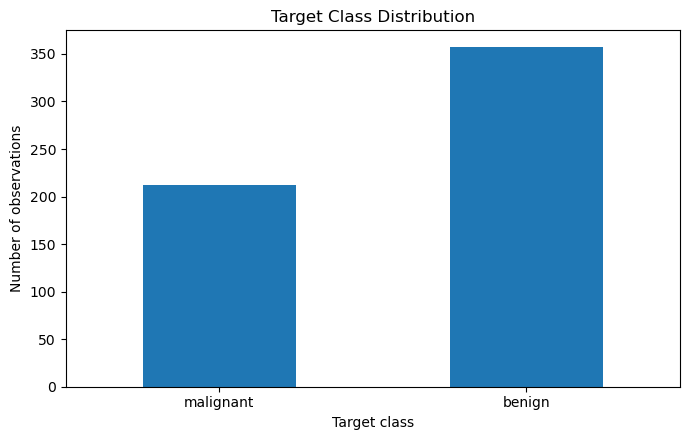

In [11]:
dataset = load_breast_cancer(as_frame=True)
X = dataset.data.copy()
y = dataset.target.copy()

dataset_summary = {
    "rows": int(X.shape[0]),
    "features": int(X.shape[1]),
    "missing_feature_values": int(X.isna().sum().sum()),
    "duplicate_feature_rows": int(X.duplicated().sum()),
    "class_counts": {LABEL_NAMES[int(k)]: int(v) for k, v in y.value_counts().sort_index().items()}
}
print(json.dumps(dataset_summary, indent=2))
display(X.head())

# Save the dataset with readable target labels for reproducibility.
X.assign(target=y.map(LABEL_NAMES)).to_csv(OUTPUT_DIR / "breast_cancer_dataset.csv", index=False)

# Class distribution visualization.
class_counts = y.map(LABEL_NAMES).value_counts().reindex(["malignant", "benign"])
ax = class_counts.plot(kind="bar", figsize=(7, 4.5))
ax.set_title("Target Class Distribution")
ax.set_ylabel("Number of observations")
ax.set_xlabel("Target class")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "01_class_distribution.png", dpi=180)
plt.show()

## 2. Train/test split and preprocessing design

The data is split into 80% training and 20% test data using stratification and a fixed random seed. The test set is held back until final evaluation.

Median imputation is included inside each pipeline for robustness, although this version of the feature matrix contains no missing values. Logistic regression uses `StandardScaler` because feature scale affects its optimization. Random forest does not require scaling. Keeping transformations inside a pipeline means each cross-validation fold learns preprocessing parameters from its own training portion, reducing data leakage.

All predictors are already numeric, so categorical encoding is not required. The primary feature transformation is standardization for logistic regression.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(f"Training observations: {len(X_train)}")
print(f"Test observations: {len(X_test)}")
print("Training class counts:", y_train.map(LABEL_NAMES).value_counts().to_dict())
print("Test class counts:", y_test.map(LABEL_NAMES).value_counts().to_dict())

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

logistic_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
])
random_forest_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300, random_state=RANDOM_STATE, class_weight="balanced"
    ))
])

Training observations: 455
Test observations: 114
Training class counts: {'benign': 285, 'malignant': 170}
Test class counts: {'benign': 72, 'malignant': 42}


## 3. Model comparison with five-fold cross-validation

Logistic regression is a comparatively interpretable linear baseline. Random forest is included as a tree-ensemble model that can represent nonlinear relationships and interactions.

Five-fold stratified cross-validation is applied to the training set. We report mean and standard deviation for accuracy, precision, recall, F1, and ROC-AUC. Scalar precision/recall/F1 use benign (`1`) as the positive class; the final classification report will show both classes. Cross-validation results support model selection, while the test set remains untouched.

,Model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std
0,Logistic Regression,0.9780,0.0110,0.9795,0.0181,0.9860,0.0147,0.9825,0.0087,0.9959,0.0055
1,Random Forest,0.9626,0.0184,0.9718,0.0096,0.9684,0.0260,0.9700,0.0151,0.9923,0.0055


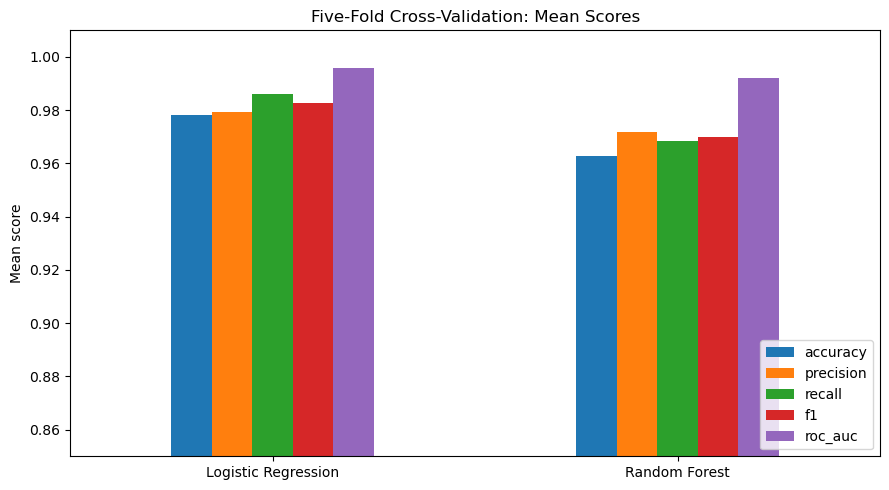

In [13]:
SCORING = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}
cv_rows = []
for model_name, pipeline in [
    ("Logistic Regression", logistic_pipeline),
    ("Random Forest", random_forest_pipeline)
]:
    result = cross_validate(
        pipeline, X_train, y_train, cv=cv, scoring=SCORING,
        return_train_score=False
    )
    row = {"Model": model_name}
    for metric in SCORING:
        row[f"{metric}_mean"] = result[f"test_{metric}"].mean()
        row[f"{metric}_std"] = result[f"test_{metric}"].std(ddof=1)
    cv_rows.append(row)

cv_results = pd.DataFrame(cv_rows)
display(cv_results.round(4))
cv_results.to_csv(OUTPUT_DIR / "cross_validation_metrics.csv", index=False)

plot_metrics = ["accuracy_mean", "precision_mean", "recall_mean", "f1_mean", "roc_auc_mean"]
plot_data = cv_results.set_index("Model")[plot_metrics].rename(
    columns={column: column.replace("_mean", "") for column in plot_metrics}
)
ax = plot_data.plot(kind="bar", figsize=(9, 5))
ax.set_title("Five-Fold Cross-Validation: Mean Scores")
ax.set_ylabel("Mean score")
ax.set_ylim(0.85, 1.01)
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "02_cross_validation_comparison.png", dpi=180)
plt.show()

## 4. Hyperparameter tuning

`GridSearchCV` tests regularization strengths `C = [0.01, 0.1, 1, 10, 100]` for logistic regression. ROC-AUC is the selection metric. All tuning is performed using training data and cross-validation; the held-out test set is not used to choose `C`.

The selected parameter and all tested scores are saved to `outputs/logistic_grid_search_results.csv`.

In [14]:
param_grid = {"model__C": [0.01, 0.1, 1, 10, 100]}
grid = GridSearchCV(
    logistic_pipeline, param_grid, cv=cv, scoring="roc_auc",
    n_jobs=-1, return_train_score=True
)
grid.fit(X_train, y_train)
best_logistic = grid.best_estimator_
print("Best parameters:", grid.best_params_)
print(f"Best mean training-fold ROC-AUC: {grid.best_score_:.4f}")

grid_results = pd.DataFrame(grid.cv_results_)[
    ["param_model__C", "mean_test_score", "std_test_score", "rank_test_score"]
]
display(grid_results)
grid_results.to_csv(OUTPUT_DIR / "logistic_grid_search_results.csv", index=False)

# Fit the comparison model on all training data only.
random_forest = random_forest_pipeline.fit(X_train, y_train)
best_logistic.fit(X_train, y_train)

Best parameters: {'model__C': 1}
Best mean training-fold ROC-AUC: 0.9959


,param_model__C,mean_test_score,std_test_score,rank_test_score
0,0.01,0.992570,0.004552,3
1,0.10,0.995150,0.004622,2
2,1.00,0.995872,0.004960,1
3,10.00,0.992157,0.008704,4
4,100.00,0.987616,0.010730,5


,steps,"[('imputer', ...), ('scaler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,copy,True


## 5. Held-out test evaluation

The final models are evaluated on the test set once. Metrics include accuracy, balanced accuracy, benign-class precision/recall/F1, ROC-AUC, and Matthews correlation coefficient (MCC). These complementary metrics help avoid relying on accuracy alone.

The target class distribution is unequal, so class-specific performance matters. The confusion matrix and classification report below show the number and types of errors for both labels.

In [15]:
def evaluate_model(model, X_eval, y_eval):
    predictions = model.predict(X_eval)
    probabilities_benign = model.predict_proba(X_eval)[:, 1]
    metrics = {
        "Accuracy": accuracy_score(y_eval, predictions),
        "Balanced accuracy": balanced_accuracy_score(y_eval, predictions),
        "Precision (benign)": precision_score(y_eval, predictions, pos_label=1),
        "Recall (benign)": recall_score(y_eval, predictions, pos_label=1),
        "F1 (benign)": f1_score(y_eval, predictions, pos_label=1),
        "ROC-AUC": roc_auc_score(y_eval, probabilities_benign),
        "Matthews correlation coefficient": matthews_corrcoef(y_eval, predictions)
    }
    return predictions, probabilities_benign, metrics

pred_lr, prob_lr, metrics_lr = evaluate_model(best_logistic, X_test, y_test)
pred_rf, prob_rf, metrics_rf = evaluate_model(random_forest, X_test, y_test)

test_metrics = pd.DataFrame([
    {"Model": "Tuned Logistic Regression", **metrics_lr},
    {"Model": "Random Forest", **metrics_rf}
])
display(test_metrics.round(4))
test_metrics.to_csv(OUTPUT_DIR / "held_out_test_metrics.csv", index=False)

print("Tuned logistic regression classification report:")
print(classification_report(
    y_test, pred_lr, labels=[0, 1],
    target_names=["malignant", "benign"], digits=4
))
print("Random forest classification report:")
print(classification_report(
    y_test, pred_rf, labels=[0, 1],
    target_names=["malignant", "benign"], digits=4
))

# Save detailed class metrics and test predictions.
class_report = pd.DataFrame(classification_report(
    y_test, pred_lr, labels=[0, 1],
    target_names=["malignant", "benign"], output_dict=True
)).T
class_report.to_csv(OUTPUT_DIR / "logistic_classification_report.csv")

predictions_table = pd.DataFrame({
    "row_index": X_test.index,
    "true_label": y_test.map(LABEL_NAMES).values,
    "logistic_prediction": pd.Series(pred_lr, index=y_test.index).map(LABEL_NAMES).values,
    "logistic_probability_benign": prob_lr,
    "random_forest_prediction": pd.Series(pred_rf, index=y_test.index).map(LABEL_NAMES).values,
    "random_forest_probability_benign": prob_rf
}).sort_values("row_index")
display(predictions_table.head(10))
predictions_table.to_csv(OUTPUT_DIR / "test_set_predictions.csv", index=False)

,Model,Accuracy,Balanced accuracy,Precision (benign),Recall (benign),F1 (benign),ROC-AUC,Matthews correlation coefficient
0,Tuned Logistic Regression,0.9825,0.9812,0.9861,0.9861,0.9861,0.9954,0.9623
1,Random Forest,0.9474,0.9435,0.9583,0.9583,0.9583,0.9937,0.8869


Tuned logistic regression classification report:
              precision    recall  f1-score   support

   malignant     0.9762    0.9762    0.9762        42
      benign     0.9861    0.9861    0.9861        72

    accuracy                         0.9825       114
   macro avg     0.9812    0.9812    0.9812       114
weighted avg     0.9825    0.9825    0.9825       114

Random forest classification report:
              precision    recall  f1-score   support

   malignant     0.9286    0.9286    0.9286        42
      benign     0.9583    0.9583    0.9583        72

    accuracy                         0.9474       114
   macro avg     0.9435    0.9435    0.9435       114
weighted avg     0.9474    0.9474    0.9474       114



,row_index,true_label,logistic_prediction,logistic_probability_benign,random_forest_prediction,random_forest_probability_benign
96,1,malignant,malignant,2.927337e-05,malignant,0.046667
102,14,malignant,malignant,3.172357e-02,malignant,0.123333
67,20,benign,benign,9.976373e-01,benign,0.983333
26,23,malignant,malignant,4.835957e-09,malignant,0.010000
101,24,malignant,malignant,7.578684e-09,malignant,0.000000
35,41,malignant,malignant,1.879893e-01,benign,0.763333
85,51,benign,benign,9.990827e-01,benign,0.983333
44,64,malignant,malignant,1.712219e-03,malignant,0.023333
82,70,malignant,malignant,4.620398e-06,malignant,0.000000
53,73,malignant,benign,9.087281e-01,benign,0.586667


,pred_malignant,pred_benign
true_malignant,41,1
true_benign,1,71


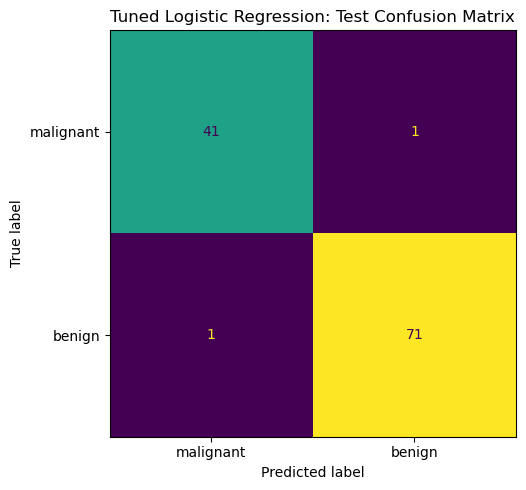

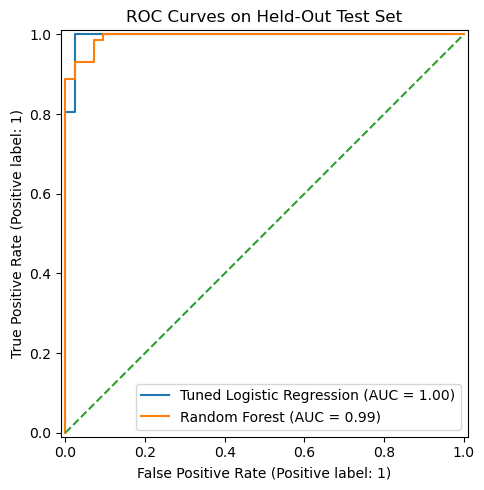

In [16]:
# Confusion matrix: rows are true labels; columns are predicted labels.
cm = confusion_matrix(y_test, pred_lr, labels=[0, 1])
cm_table = pd.DataFrame(
    cm, index=["true_malignant", "true_benign"],
    columns=["pred_malignant", "pred_benign"]
)
display(cm_table)
cm_table.to_csv(OUTPUT_DIR / "logistic_confusion_matrix.csv")

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["malignant", "benign"]).plot(
    ax=ax, values_format="d", colorbar=False
)
ax.set_title("Tuned Logistic Regression: Test Confusion Matrix")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "03_logistic_confusion_matrix.png", dpi=180)
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
RocCurveDisplay.from_predictions(y_test, prob_lr, name="Tuned Logistic Regression", ax=ax)
RocCurveDisplay.from_predictions(y_test, prob_rf, name="Random Forest", ax=ax)
ax.plot([0, 1], [0, 1], "--", label="Chance")
ax.set_title("ROC Curves on Held-Out Test Set")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "04_roc_curves.png", dpi=180)
plt.show()

## 6. Feature importance and error interpretation

Permutation importance shuffles one feature at a time and measures the resulting change in ROC-AUC. A larger decrease suggests that the fitted model relies more on that feature for ranking predictions on this test sample. This is a model diagnostic, not a causal explanation. Correlated predictors may share or mask importance.

The confusion matrix is `[[41, 1], [1, 71]]` when rows are true labels (malignant, benign) and columns are predicted labels (malignant, benign). Thus, 41 malignant and 71 benign observations are correctly classified; one malignant observation is predicted benign, and one benign observation is predicted malignant. This demonstrates why overall accuracy alone is insufficient.

In a real medical context, a malignant observation predicted benign is a serious type of error. However, this dataset and model are educational only and must not be used for diagnosis.

,feature,importance_mean,importance_std
24,worst smoothness,0.00364,0.00203
27,worst concave points,0.00329,0.00270
13,area error,0.00326,0.00277
10,radius error,0.00316,0.00208
23,worst area,0.00294,0.00248
20,worst radius,0.00283,0.00279
21,worst texture,0.00265,0.00300
22,worst perimeter,0.00198,0.00197
7,mean concave points,0.00188,0.00178
26,worst concavity,0.00179,0.00185


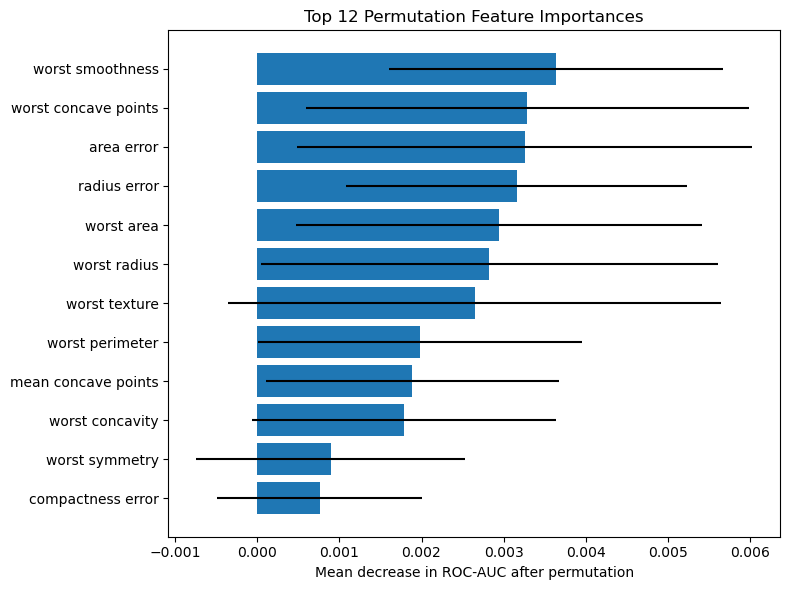

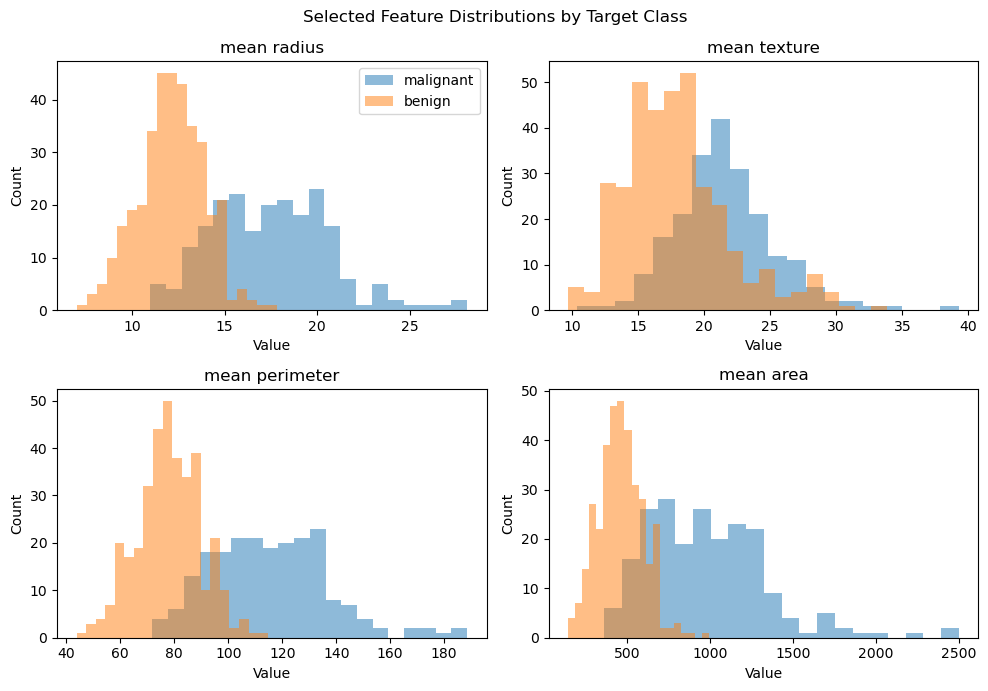

In [17]:
permutation = permutation_importance(
    best_logistic, X_test, y_test, n_repeats=20,
    random_state=RANDOM_STATE, scoring="roc_auc", n_jobs=-1
)
importance = pd.DataFrame({
    "feature": X.columns,
    "importance_mean": permutation.importances_mean,
    "importance_std": permutation.importances_std
}).sort_values("importance_mean", ascending=False)
display(importance.head(15).round(5))
importance.to_csv(OUTPUT_DIR / "permutation_feature_importance.csv", index=False)

top = importance.head(12).sort_values("importance_mean")
plt.figure(figsize=(8, 6))
plt.barh(top["feature"], top["importance_mean"], xerr=top["importance_std"])
plt.title("Top 12 Permutation Feature Importances")
plt.xlabel("Mean decrease in ROC-AUC after permutation")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "05_permutation_feature_importance.png", dpi=180)
plt.show()

# Distribution examples for selected features; these are exploratory, not causal.
selected_features = ["mean radius", "mean texture", "mean perimeter", "mean area"]
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, feature in zip(axes.flat, selected_features):
    for class_id, class_name in [(0, "malignant"), (1, "benign")]:
        ax.hist(X.loc[y == class_id, feature], bins=20, alpha=0.5, label=class_name)
    ax.set_title(feature)
    ax.set_xlabel("Value")
    ax.set_ylabel("Count")
axes.flat[0].legend()
fig.suptitle("Selected Feature Distributions by Target Class")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "06_selected_feature_distributions.png", dpi=180)
plt.show()

## 7. Experiment summary and output files

The `outputs/` directory contains the artifacts produced by this notebook:
- `breast_cancer_dataset.csv` — feature data and readable target labels.
- `cross_validation_metrics.csv` — five-fold means and standard deviations.
- `held_out_test_metrics.csv` — held-out metrics for both models.
- `logistic_classification_report.csv` — per-class precision, recall, F1, and support.
- `logistic_confusion_matrix.csv` — raw confusion-matrix counts.
- `test_set_predictions.csv` — true labels, predictions, and predicted benign probabilities.
- `logistic_grid_search_results.csv` — scores for each tested regularization value.
- `permutation_feature_importance.csv` — feature-importance means and standard deviations.
- `experiment_summary.json` — key dataset, split, tuning, and test-result details.
- `figures/` — six charts used for analysis and reporting.

### Conclusion
This experiment compares a linear classifier with a tree ensemble, uses cross-validation for model comparison, tunes logistic regression without touching the test set, and evaluates final performance on held-out observations. Logistic regression performed better on test accuracy and benign-class F1 in this split, while both models had high ROC-AUC. Results should be treated cautiously because this is a small curated dataset. External validation, probability calibration, threshold analysis, and expert oversight would be required before any real-world use.

In [18]:
experiment_summary = {
    "dataset": {
        "rows": int(X.shape[0]),
        "features": int(X.shape[1]),
        "missing_feature_values": int(X.isna().sum().sum()),
        "duplicate_feature_rows": int(X.duplicated().sum()),
        "class_counts": {LABEL_NAMES[int(k)]: int(v) for k, v in y.value_counts().sort_index().items()}
    },
    "split": {
        "train_rows": int(len(X_train)),
        "test_rows": int(len(X_test)),
        "test_fraction": 0.20,
        "random_state": RANDOM_STATE
    },
    "tuning": {
        "best_C": float(grid.best_params_["model__C"]),
        "best_mean_cv_roc_auc": float(grid.best_score_)
    },
    "confusion_matrix_labels": ["malignant", "benign"],
    "confusion_matrix": cm.tolist(),
    "test_metrics": {
        "Tuned Logistic Regression": {k: float(v) for k, v in metrics_lr.items()},
        "Random Forest": {k: float(v) for k, v in metrics_rf.items()}
    }
}
(OUTPUT_DIR / "experiment_summary.json").write_text(
    json.dumps(experiment_summary, indent=2), encoding="utf-8"
)
print("Saved experiment summary to", OUTPUT_DIR / "experiment_summary.json")
print("Output files:")
for path in sorted(OUTPUT_DIR.rglob("*")):
    if path.is_file():
        print("-", path.as_posix())

Saved experiment summary to outputs\experiment_summary.json
Output files:
- outputs/breast_cancer_dataset.csv
- outputs/cross_validation_metrics.csv
- outputs/experiment_summary.json
- outputs/figures/01_class_distribution.png
- outputs/figures/02_cross_validation_comparison.png
- outputs/figures/03_logistic_confusion_matrix.png
- outputs/figures/04_roc_curves.png
- outputs/figures/05_permutation_feature_importance.png
- outputs/figures/06_selected_feature_distributions.png
- outputs/held_out_test_metrics.csv
- outputs/logistic_classification_report.csv
- outputs/logistic_confusion_matrix.csv
- outputs/logistic_grid_search_results.csv
- outputs/permutation_feature_importance.csv
- outputs/test_set_predictions.csv
